# SolarSentinel: first model exploration

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/adamajane/artificial-intelligence-systems-egn6216/blob/main/training_experiments.ipynb)

**What this is.** The first model experiments for SolarSentinel: one AI component run end to end on development
data, evaluated, inspected for errors and practical constraints, then one targeted change.
Two ImageNet-pretrained models are compared with an identical recipe: **ResNet-18 (CNN, run A)** and **DeiT-Tiny
(vision transformer, run B)**. Run C applies one change, chosen by a rule fixed before the runs (section 10).

**Run summary (all numbers from the outputs below; 630 val cases, 210 positives, 167 HARPs).** ResNet-18 (A)
reached val TSS 0.648 (95% HARP-bootstrap CI 0.520–0.744) and DeiT-Tiny (B) 0.626 (0.510–0.712); the difference is
not distinguishable from zero (CI of B − A: −0.110 to +0.072), and over three seeds the means are 0.631 and 0.627.
Run C (A without flagged training negatives) gave 0.633, also no clear change. Both models meet the size and
latency targets; the image download (about 1,240 cutouts/h) is the bottleneck. **Preliminary:** one subsample of
val, thresholds picked on the same cases, short training.

**Where things are.** Plan: [`docs/2-model-experiment-plan.md`](docs/2-model-experiment-plan.md). Data rules:
[`configs/data.yaml`](configs/data.yaml). Experiment settings (seeds, subset sizes, recipe, model IDs):
[`configs/experiments.yaml`](configs/experiments.yaml). Logic: `src/solarsentinel/models/` (`targets.py`,
`dataset.py`, `nets.py`, `metrics.py`, `train.py`). Run records: `experiments/results/<run_id>.json` and
`<run_id>_val_preds.parquet`. Data: the public bucket `gs://solarsentinel_ai-systems-egn6216`, read anonymously.

**How to run.** Locally: `uv sync`, then
`uv run jupyter nbconvert --to notebook --execute --inplace training_experiments.ipynb`. Colab: use the badge; the
first code cell clones the repo and installs `timm`.

## 1. Role of AI, candidates, and the non-AI stages

**What the AI does.** The AI component takes one 128×128 SHARP radial-field (Br) magnetogram cutout of a
NOAA-numbered active region at a 6-hour slot, and outputs the probability that this region produces a flare of class
≥M1.0 (GOES science scale) within the next 24 hours. The alert is a policy on top of that probability: a threshold
chosen on validation (max TSS). Changing the alert rule does not need retraining.

**Candidates.** The comparison is a CNN against a vision transformer with similar ImageNet accuracy (both roughly
low-70s % top-1), trained with the same data, preprocessing and recipe, so the difference comes from architecture
(local convolutional bias vs. global attention):

| ID | Model | Source (Hugging Face Hub, via `timm`) | Params | License |
| --- | --- | --- | --- | --- |
| A | ResNet-18 | `timm/resnet18.a1_in1k` | 11.2 M (1 input channel, 1 output) | Apache-2.0 |
| B | DeiT-Tiny/16 | `timm/deit_tiny_patch16_224.fb_in1k` | 5.4 M (same) | Apache-2.0 |

Named but not run here: the ResNet-50 vs. DeiT-Small scale-up pair (about 90–100 MB each, over the 50 MB bundle
target); EfficientNet-B0 and ConvNeXt-Atto; a hybrid CNN embedding + the 18 SHARP parameters; NASA-IBM Surya
(full-disk, multi-channel; a thesis direction); feature-based models on SHARP parameters (parked per the professor).

**Why these two first.** They are the smallest members of each family that fit the runtime bundle target (< 50 MB,
CPU-only), they load pretrained in one `timm` call, and a ~1-minute training run on a laptop fits the time budget.
DeiT was picked as the transformer because it was designed to train with less data, and data-hungriness is exactly
what this comparison tests.

**Non-AI stages (deterministic, verified by the data step's known-value checks):** 6-h slot sampling (±60 min,
QUALITY preference), NOAA and ±60° longitude filters, flare-to-region attribution (methods a–d), 24-h labelling,
the chronological HARP-grouped split, Br normalization (one fitted constant), threshold selection and the alert rule.

**Stage explored first:** the per-region flare classifier (proposal C5), because it is the only learned stage.

## 2. Setup

In [1]:
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:  # clone the repo for the solarsentinel package and configs; data comes from the public bucket
    if not Path("artificial-intelligence-systems-egn6216").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/adamajane/artificial-intelligence-systems-egn6216"], check=True)
    %cd artificial-intelligence-systems-egn6216
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "gcsfs", "drms", "astropy", "python-dotenv", "scikit-image"], check=True)
    sys.path.insert(0, "src")
print("Colab" if IN_COLAB else "local kernel", "| Python", sys.version.split()[0])

local kernel | Python 3.13.5


In [2]:
import copy
import json
import platform
import tempfile
import time
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm, imported by timm

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import timm
import torch

from solarsentinel import storage
from solarsentinel.config import load_config, load_experiments
from solarsentinel.models import dataset, metrics, nets, train

warnings.filterwarnings("ignore", category=UserWarning, module="torch")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

FME = load_experiments()["fme"]
RECIPE, EV = FME["recipe"], FME["eval"]
DEV = nets.device()  # cuda -> mps -> cpu
print(f"python {platform.python_version()} | torch {torch.__version__} | timm {timm.__version__} | sklearn {sklearn.__version__}")
print(f"device: {DEV} | machine: {platform.machine()} {platform.system()} | seed: {RECIPE['seed']}")
print("dataset version:", load_config()["storage"]["dataset_version"], "| cutout subset:", FME["prefix"])

python 3.13.5 | torch 2.14.1 | timm 1.0.30 | sklearn 1.9.1
device: mps | machine: arm64 Darwin | seed: 42
dataset version: v1 | cutout subset: processed/v1/experiments/fme


## 3. Data: load, join, check, prepare

**What is loaded.** `processed/v1/observations.parquet` (one row per region and 6-h slot, labels and flags) and the
cutouts of a **stratified subset** (`processed/v1/experiments/fme/`). Only 139 pilot cutouts existed
before this step, all from training, and the full image download takes about 25.6 h. So a target list was built
(`solarsentinel.models.targets`, seed 42): 233 val positives (VP, all of them), 466 of 5,604 val negatives (VN),
233 of 1,086 train positives (TP), 466 of 23,965 train negatives (TN), interleaved as VP, VN, VN, TP, TN, TN so
that **whatever prefix finished downloading is a stratified sample** (about 1:2 positives to negatives in both
splits). Negatives were sampled from all negatives, flagged ones included. The JSOC export was stopped after a
fixed time and this notebook uses what arrived.

**Split.** Section 6.5 of the proposal: chronological and grouped by HARP. Train 2011–2014, validation 2015,
replay 2016–2017. **Replay is the final test set and is never loaded here** (`load_cutouts` refuses it).

In [3]:
targets = pd.read_parquet(dataset._pull(f"{FME['prefix']}/targets.parquet"))
X, meta = dataset.load_cutouts(f"{FME['prefix']}/cutouts", splits=("train", "val"))
meta = meta.merge(targets[["HARPNUM", "T_REC", "stratum", "priority"]], on=["HARPNUM", "T_REC"], how="left", validate="one_to_one")
assert meta.stratum.notna().all(), "a cutout that is not in the target list"
print("images:", X.shape, X.dtype, "| metadata rows:", len(meta))
print("value range (Gauss): min %.0f, max %.0f, |Br| p50 %.0f" % (X.min(), X.max(), np.median(np.abs(X.astype(np.float32)))))

got = meta.stratum.value_counts()
listed = targets.stratum.value_counts()
tier1 = targets[targets.tier == 1].stratum.value_counts()
counts = pd.DataFrame({"listed (tier 1)": tier1, "listed (all tiers)": listed, "downloaded": got}).fillna(0).astype(int)
counts["dropped (no file)"] = counts["listed (all tiers)"] - counts["downloaded"]
counts.loc[["VP", "VN", "TP", "TN"]]

images: (1260, 128, 128) float16 | metadata rows: 1260


value range (Gauss): min -4212, max 3468, |Br| p50 29


,listed (tier 1),listed (all tiers),downloaded,dropped (no file)
stratum,,,,
VP,233,233,210,23
VN,466,466,420,46
TP,233,466,210,256
TN,466,932,420,512


In [4]:
done = targets.merge(meta[["HARPNUM", "T_REC"]], on=["HARPNUM", "T_REC"], how="left", indicator=True)
prefix_done = (done._merge == "both").to_numpy()
last = int(np.flatnonzero(prefix_done).max()) if prefix_done.any() else -1
print(f"downloaded targets form a prefix of the priority order: {bool(prefix_done[: last + 1].all())} (last priority {last})")

tr_m, va_m = meta[meta.split == "train"].reset_index(drop=True), meta[meta.split == "val"].reset_index(drop=True)
X_tr, X_va = X[(meta.split == "train").to_numpy()], X[(meta.split == "val").to_numpy()]
balance = pd.DataFrame({
    s: {"cases": len(m), "positives": int(m.label.sum()), "positive rate": round(m.label.mean(), 3),
        "HARPs": m.HARPNUM.nunique(), "flagged negatives (has_unattributed_mx)": int(((m.label == 0) & m.has_unattributed_mx).sum())}
    for s, m in (("train", tr_m), ("val", va_m))
}).T
balance

downloaded targets form a prefix of the priority order: True (last priority 1259)


,cases,positives,positive rate,HARPs,flagged negatives (has_unattributed_mx)
train,630.0,210.0,0.333,371.0,63.0
val,630.0,210.0,0.333,167.0,58.0


**Leakage checks.** Train and val share no HARP; no label or flag column is a model input (the model sees only the
image tensor); the clip constant `c` is fitted on training pixels only.

In [5]:
assert not set(tr_m.HARPNUM) & set(va_m.HARPNUM), "train and val share a HARP"
assert set(meta.split) <= {"train", "val"} and not meta.slot_time.dt.year.between(2016, 2017).any(), "replay rows present"
c = dataset.clip_constant(X_tr, RECIPE["clip_percentile"])
print(f"c = {RECIPE['clip_percentile']}th percentile of |Br| over {X_tr.size:,} training pixels = {c:.1f} G (input = clip(Br, -c, c) / c)")
print(f"val pixels beyond ±c: {(np.abs(X_va.astype(np.float32)) > c).mean():.2%} (train: {(np.abs(X_tr.astype(np.float32)) > c).mean():.2%})")

c = 99.5th percentile of |Br| over 10,321,920 training pixels = 1050.0 G (input = clip(Br, -c, c) / c)
val pixels beyond ±c: 0.48% (train: 0.50%)


**Data handling: filled, dropped, left unchanged.**

In [6]:
notes = {
    "NaN pixels (filled with 0 by the pipeline before resizing): val images with nan_fraction > 0": int((va_m.nan_fraction > 0).sum()),
    "NaN pixels: train images with nan_fraction > 0": int((tr_m.nan_fraction > 0).sum()),
    "max nan_fraction (all used images)": round(float(meta.nan_fraction.max()), 4),
    "targets dropped because no file arrived before the stop time": int(counts["dropped (no file)"].sum()),
    "quality_nonzero rows kept (flag only)": int(meta.quality_nonzero.sum()),
    "flagged negatives kept (label-noise flag, never an input)": int(((meta.label == 0) & meta.has_unattributed_mx).sum()),
    "aspect ratio orig_nx/orig_ny (stretched to 128x128): min / median / max": " / ".join(f"{v:.2f}" for v in (meta.orig_nx / meta.orig_ny).quantile([0, 0.5, 1])),
}
pd.Series(notes, name="value").to_frame()

,value
NaN pixels (filled with 0 by the pipeline before resizing): val images with nan_fraction > 0,8
NaN pixels: train images with nan_fraction > 0,31
max nan_fraction (all used images),0.4817
targets dropped because no file arrived before the stop time,837
quality_nonzero rows kept (flag only),2
"flagged negatives kept (label-noise flag, never an input)",121
aspect ratio orig_nx/orig_ny (stretched to 128x128): min / median / max,0.74 / 2.05 / 4.34


Missing SHARP summary values (5–53 rows in the full table) do not matter here: image models do not read them. The
pipeline does not rebalance classes; imbalance is handled at training time by a weighted loss (section 4).
Examples of the input as the model sees it (after clipping to ±c and scaling to [−1, 1]; red = positive polarity):

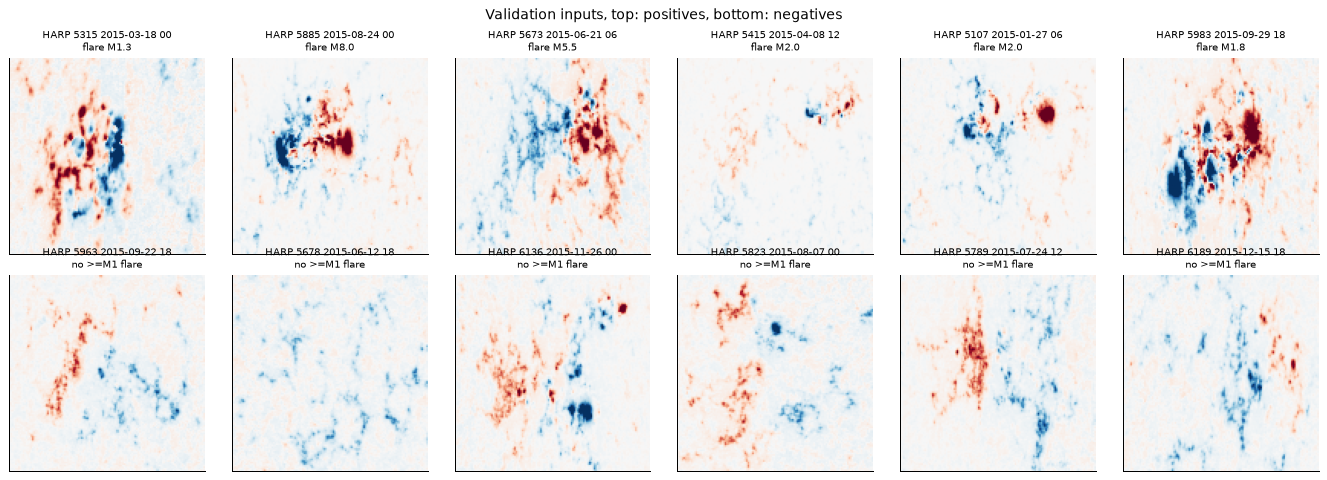

In [7]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
rng = np.random.default_rng(0)
for row, lab in enumerate((1, 0)):
    idx = rng.choice(np.flatnonzero((va_m.label == lab).to_numpy()), 6, replace=False)
    for ax, i in zip(axes[row], idx):
        ax.imshow(np.clip(X_va[i].astype(np.float32), -c, c) / c, origin="lower", cmap="RdBu_r", vmin=-1, vmax=1)
        r = va_m.iloc[i]
        ax.set_title(f"HARP {r.HARPNUM} {str(r.slot_time)[:13]}\n{'flare ' + r.label_class if lab else 'no >=M1 flare'}", fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Validation inputs, top: positives, bottom: negatives", fontsize=11)
fig.tight_layout()

## 4. Model configuration (recorded before any tuning)

Both models: `timm.create_model(name, pretrained=True, in_chans=1, num_classes=1)`; DeiT also gets `img_size=128`.
`in_chans=1` sums the pretrained RGB weights of the first layer. For DeiT, `img_size=128` resamples the learned
14×14 position embeddings to 8×8 (64 patches of 16×16). **No HF/timm image transform** is used: the inputs are
physical values in Gauss, not 0–255 pixels, so ImageNet mean/std would be meaningless.

Class imbalance is handled once, by the loss: `BCEWithLogitsLoss(pos_weight = n_neg / n_pos)` of the training set.
No 0.5 threshold and no accuracy anywhere; the threshold is chosen on validation (max TSS).

In [8]:
pos_weight = float((tr_m.label == 0).sum() / tr_m.label.sum())
config = pd.Series({
    "dataset": f"processed/v1 observations + {FME['prefix']}/cutouts",
    "train / val cases": f"{len(tr_m)} / {len(va_m)}",
    "input": f"1x128x128, clip(Br, ±c)/c, c = {c:.1f} G",
    "augmentation (train)": ", ".join(f"{k} p={v}" for k, v in RECIPE["augment"].items()),
    "loss": f"BCEWithLogitsLoss(pos_weight={pos_weight:.3f})",
    "optimizer": f"AdamW lr {RECIPE['lr']}, weight decay {RECIPE['weight_decay']}, cosine, {RECIPE['warmup_epochs']} warmup epoch",
    "budget": f"{RECIPE['epochs']} epochs, batch {RECIPE['batch_size']}, fp32, all layers trainable",
    "selection": "final epoch (no early stopping)",
    "seed": RECIPE["seed"],
    "A": f"{FME['models']['A']['name']} ({FME['models']['A']['hf_repo']}, {FME['models']['A']['license']})",
    "B": f"{FME['models']['B']['name']} img_size=128 ({FME['models']['B']['hf_repo']}, {FME['models']['B']['license']})",
    "device": str(DEV),
}, name="setting").to_frame()
config

,setting
dataset,processed/v1 observations + processed/v1/exper...
train / val cases,630 / 630
input,"1x128x128, clip(Br, ±c)/c, c = 1050.0 G"
augmentation (train),"hflip p=0.5, vflip p=0.5, polarity p=0.5"
loss,BCEWithLogitsLoss(pos_weight=2.000)
optimizer,"AdamW lr 0.0001, weight decay 0.05, cosine, 1 ..."
budget,"15 epochs, batch 32, fp32, all layers trainable"
selection,final epoch (no early stopping)
seed,42
A,"resnet18.a1_in1k (timm/resnet18.a1_in1k, Apach..."


## 5. Smoke test on the 139 pilot cutouts

End to end first: load → train 2 epochs → predict → metrics → run record, for both models. The pilot is one week of
training data (2014-10-20..27), so two of its HARPs stand in as validation here. **This only shows that the code
runs; the numbers say nothing about model quality** (9 HARPs, 2 epochs).

In [9]:
Xp, mp = dataset.load_cutouts("processed/v1/cutouts", splits=("train",))
hold = mp.HARPNUM.isin([4698, 4678]).to_numpy()
smoke = copy.deepcopy(FME)
smoke["recipe"]["epochs"], smoke["eval"]["bootstrap_reps"] = 2, 50
smoke["results_dir"] = tempfile.mkdtemp(prefix="fme_smoke_")  # smoke records are not kept
cp = dataset.clip_constant(Xp[~hold], RECIPE["clip_percentile"])
rows = []
for k in "AB":
    r = train.run(f"smoke_{k}", FME["models"][k], (Xp[~hold], mp[~hold].reset_index(drop=True)), (Xp[hold], mp[hold].reset_index(drop=True)), cp, smoke)
    rows.append({"model": k, "train/val cases": f"{r['data']['n_train']}/{r['data']['n_val']}", "p range": f"{r['p'].min():.3f}–{r['p'].max():.3f}",
                 "final train loss": round(r["history"][-1]["train_loss"], 3), "s/epoch": r["timing"]["epoch_s"]})
pd.DataFrame(rows)

,model,train/val cases,p range,final train loss,s/epoch
0,A,94/45,0.487–0.611,1.247,"[1.14, 0.16]"
1,B,94/45,0.239–0.566,1.079,"[0.45, 0.16]"


## 6. Training runs A and B

Identical recipe and seed; only the architecture differs. The final epoch is evaluated.

In [10]:
TR, VA = (X_tr, tr_m), (X_va, va_m)
runs = {}
for k, rid in (("A", "fme_A_resnet18_s42"), ("B", "fme_B_deit_tiny_s42")):
    t0 = time.time()
    runs[k] = train.run(rid, FME["models"][k], TR, VA, c, FME, change="none (baseline)" if k == "A" else "architecture only")
    t = runs[k]["timing"]
    print(f"{rid}: {time.time() - t0:.0f} s total, {t['epoch_s_median']} s/epoch on {t['device']}")

fme_A_resnet18_s42: 23 s total, 1.14 s/epoch on mps


fme_B_deit_tiny_s42: 21 s total, 1.08 s/epoch on mps


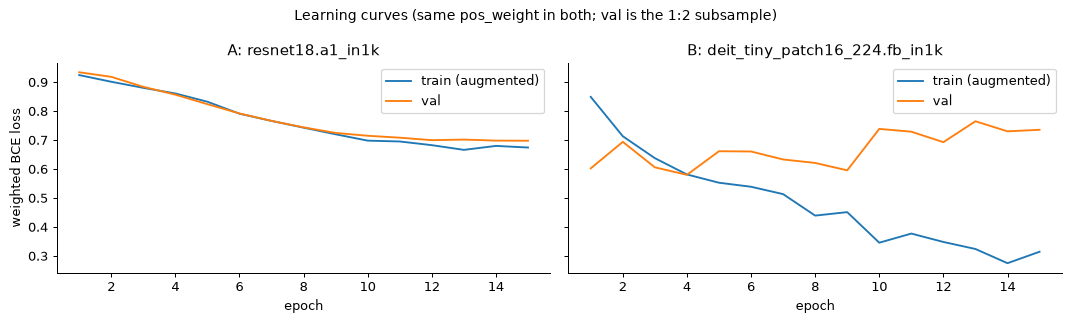

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, (k, r) in zip(axes, runs.items()):
    h = pd.DataFrame(r["history"])
    ax.plot(h.epoch, h.train_loss, label="train (augmented)")
    ax.plot(h.epoch, h.val_loss, label="val")
    ax.set_title(f"{k}: {r['model']['name']}"); ax.set_xlabel("epoch"); ax.legend()
axes[0].set_ylabel("weighted BCE loss")
fig.suptitle("Learning curves (same pos_weight in both; val is the 1:2 subsample)", fontsize=11)
fig.tight_layout()

## 7. Evaluation on validation (2015)

**Primary metric: TSS** (true skill statistic) = recall − false-alarm rate = TP/(TP+FN) − FP/(FP+TN). It is the
standard skill score for flare forecasting, it ranges from −1 to 1 (0 = no skill), and each term is computed within
one class, so it does not depend on the class ratio. That matters here twice: flares are rare (4% of val), and the
val set is negative-subsampled (about 1:2 instead of 1:24). ROC-AUC has the same property.

**Prevalence-corrected metrics.** Precision, PR-AUC and the Brier skill score depend on the class ratio, so each val
negative is weighted by 5,604 / (val negatives downloaded) and each positive by 1. They are labelled "corrected".

The threshold is the max-TSS threshold **on the same val cases**, so the max TSS is optimistic. 95% intervals come
from 1,000 bootstrap resamples of val **HARPs** (snapshots of one region are correlated), at the fixed threshold.

In [12]:
def summary_row(k, r):
    m, b = r["metrics"], r["metrics"]["bootstrap"]
    return {"run": k, "model": r["model"]["name"], "n": m["n"], "pos": m["n_pos"], "HARPs": m["n_harps"],
            "threshold": round(m["threshold"], 3), "TSS": round(m["tss"], 3), "TSS 95% CI": "[{:.3f}, {:.3f}]".format(*b["tss_ci95"]),
            "recall": round(m["pod"], 3), "false-alarm rate": round(m["pofd"], 3), "ROC-AUC": round(m["roc_auc"], 3),
            "AUC 95% CI": "[{:.3f}, {:.3f}]".format(*b["roc_auc_ci95"]), "PR-AUC*": round(m["pr_auc_corrected"], 3),
            "precision*": round(m["precision_corrected"], 3), "BSS*": round(m["bss_corrected"], 3),
            "TP/FP/FN/TN": f"{m['tp']}/{m['fp']}/{m['fn']}/{m['tn']}"}

pd.DataFrame([summary_row(k, r) for k, r in runs.items()]).set_index("run").T

run,A,B
model,resnet18.a1_in1k,deit_tiny_patch16_224.fb_in1k
n,630,630
pos,210,210
HARPs,167,167
threshold,0.498,0.108
TSS,0.648,0.626
TSS 95% CI,"[0.520, 0.744]","[0.510, 0.712]"
recall,0.838,0.848
false-alarm rate,0.19,0.221
ROC-AUC,0.878,0.873


In [13]:
y = va_m.label.to_numpy()
harps = va_m.HARPNUM.to_numpy()
w = metrics.neg_weights(y, EV["val_negatives_total"])
diff = metrics.paired_bootstrap_diff(y, runs["A"]["p"], runs["B"]["p"], harps, t_a=runs["A"]["metrics"]["threshold"],
                                     t_b=runs["B"]["metrics"]["threshold"], reps=EV["bootstrap_reps"], seed=EV["bootstrap_seed"])
print(f"TSS(B) - TSS(A): mean {diff['diff_mean']:+.3f}, 95% HARP-bootstrap CI [{diff['diff_ci95'][0]:+.3f}, {diff['diff_ci95'][1]:+.3f}], "
      f"B better in {diff['p_b_better']:.0%} of resamples")
excl = pd.DataFrame({k: {kk: round(v, 3) if isinstance(v, float) else v for kk, v in r["metrics"]["excl_flagged_val_negatives"].items()
                         if kk in ("n", "n_pos", "tss", "pod", "pofd", "roc_auc")} for k, r in runs.items()}).T
print("\nSecondary view: flagged val negatives (has_unattributed_mx) excluded, same thresholds:")
excl

TSS(B) - TSS(A): mean -0.021, 95% HARP-bootstrap CI [-0.110, +0.072], B better in 32% of resamples

Secondary view: flagged val negatives (has_unattributed_mx) excluded, same thresholds:


,n,n_pos,pod,pofd,tss,roc_auc
A,572.0,210.0,0.838,0.185,0.653,0.881
B,572.0,210.0,0.848,0.202,0.646,0.876


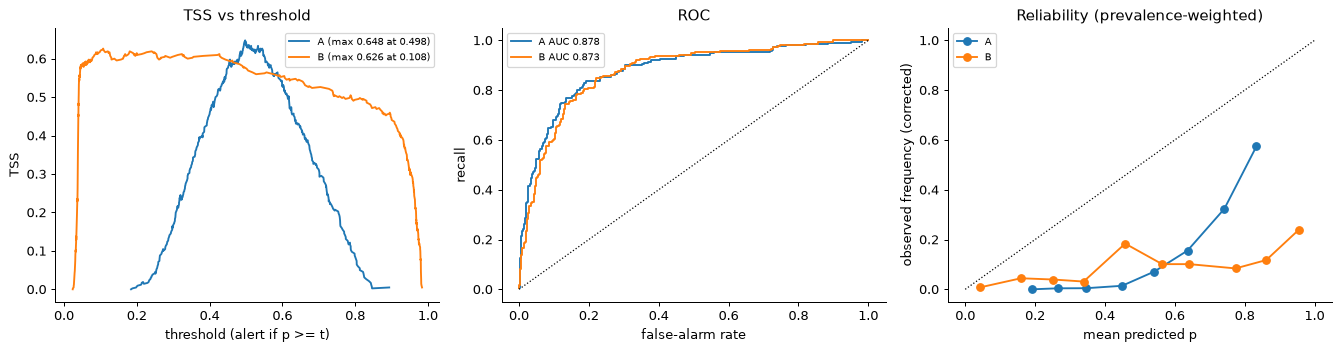

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for k, r in runs.items():
    cur = metrics.tss_curve(y, r["p"])
    axes[0].plot(cur.threshold, cur.tss, label=f"{k} (max {r['metrics']['tss']:.3f} at {r['metrics']['threshold']:.3f})")
    axes[1].plot(cur.pofd, cur.pod, label=f"{k} AUC {r['metrics']['roc_auc']:.3f}")
    rel = metrics.reliability(y, r["p"], w, EV["reliability_bins"])
    axes[2].plot(rel.p_mean, rel.observed, "o-", label=k)
axes[0].set(xlabel="threshold (alert if p >= t)", ylabel="TSS", title="TSS vs threshold")
axes[1].plot([0, 1], [0, 1], "k:", lw=1); axes[1].set(xlabel="false-alarm rate", ylabel="recall", title="ROC")
axes[2].plot([0, 1], [0, 1], "k:", lw=1); axes[2].set(xlabel="mean predicted p", ylabel="observed frequency (corrected)", title="Reliability (prevalence-weighted)")
for ax in axes: ax.legend(fontsize=8)
fig.tight_layout()

The probabilities are not calibrated: the weighted loss and the subsampling both push them up. Calibration is a later
milestone (proposal target PR2, Brier skill score > 0); the reliability diagram above shows the starting point.

## 8. Error analysis

For the run with the higher val TSS: the 5 most confident false positives (highest p among negatives) and the 5 most
confident false negatives (lowest p among positives), with the context needed to judge them.

In [15]:
best = max(runs, key=lambda k: runs[k]["metrics"]["tss"])
rb = runs[best]
t_best = rb["metrics"]["threshold"]
err = va_m.assign(p=rb["p"], aspect=(va_m.orig_nx / va_m.orig_ny).round(2))
fp = err[(err.label == 0) & (err.p >= t_best)].nlargest(5, "p")
fn = err[(err.label == 1) & (err.p < t_best)].nsmallest(5, "p")
cols = ["p", "HARPNUM", "NOAA_AR", "slot_time", "label_class", "has_unattributed_mx", "multi_noaa", "USFLUX", "LON_FWT", "aspect", "nan_fraction"]
print(f"best run: {best} ({rb['model']['name']}), threshold {t_best:.3f}; false positives {rb['metrics']['fp']}, false negatives {rb['metrics']['fn']}")
shown = pd.concat([fp.assign(error="FP"), fn.assign(error="FN")])
shown[["error", *cols]].reset_index(drop=True)

best run: A (resnet18.a1_in1k), threshold 0.498; false positives 80, false negatives 34


,error,p,HARPNUM,NOAA_AR,slot_time,label_class,has_unattributed_mx,multi_noaa,USFLUX,LON_FWT,aspect,nan_fraction
0,FP,0.846447,5298,12297,2015-03-10 06:00:00+00:00,C6.7,True,False,2.817943e+22,-38.564320,1.66,0.0
1,FP,0.783228,5885,12403,2015-08-25 00:00:00+00:00,C6.1,False,False,5.827521e+22,15.684879,2.05,0.0
2,FP,0.781989,5541,12339,2015-05-08 18:00:00+00:00,C4.3,False,True,6.785875e+22,-38.411736,2.71,0.0
3,FP,0.743790,6206,12473,2015-12-25 00:00:00+00:00,C4.3,False,False,3.403022e+22,-36.251057,2.40,0.0
4,FP,0.730766,6206,12473,2015-12-23 18:00:00+00:00,<NA>,True,False,3.400202e+22,-53.347870,2.40,0.0
5,FN,0.217098,6060,12441,2015-11-02 00:00:00+00:00,M1.0,False,False,7.700362e+20,18.802847,1.68,0.0
6,FN,0.250693,6060,12441,2015-11-01 18:00:00+00:00,M1.0,False,False,6.476014e+20,15.075912,1.68,0.0
7,FN,0.272377,5461,12332,2015-04-22 00:00:00+00:00,M1.5,False,False,1.137354e+21,19.076307,2.64,0.0
8,FN,0.297696,5461,12332,2015-04-22 06:00:00+00:00,M1.5,False,False,2.024812e+21,21.171198,2.64,0.0
9,FN,0.312296,5990,12428,2015-09-28 06:00:00+00:00,M1.0,True,False,9.116907e+20,53.924332,2.52,0.0


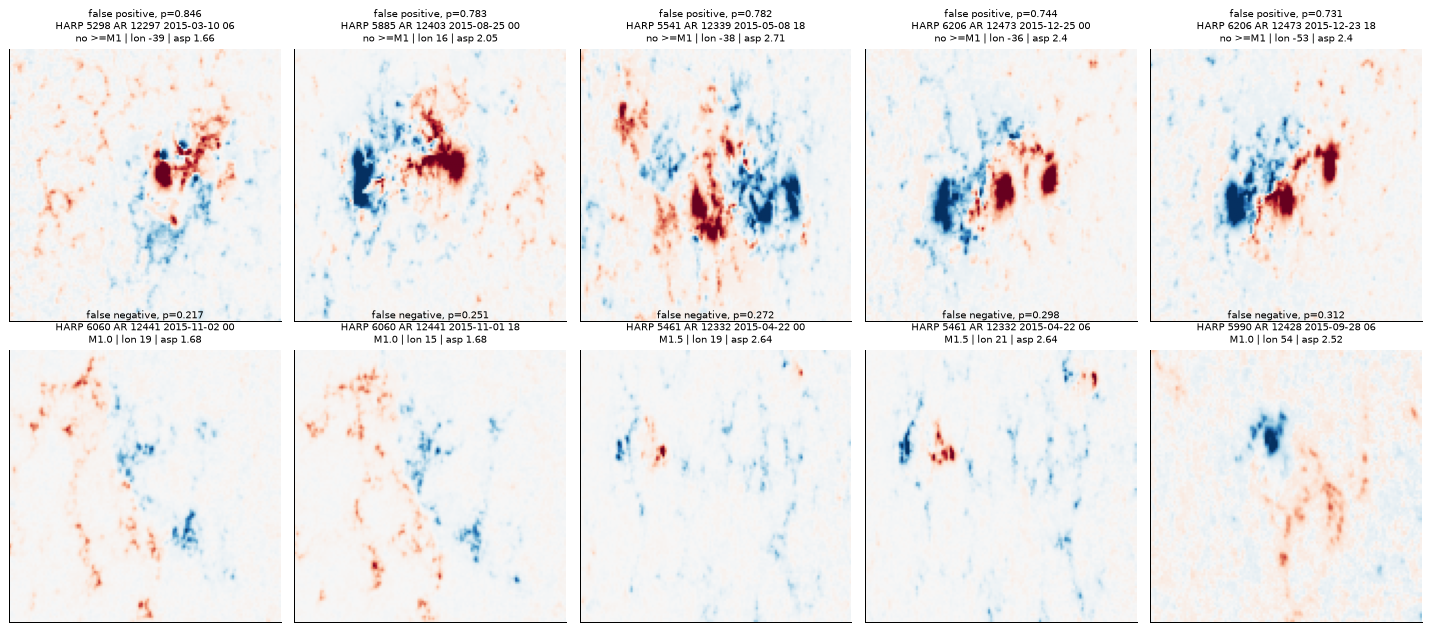

In [16]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for row, (name, g) in enumerate((("false positive", fp), ("false negative", fn))):
    for ax, (i, r) in zip(axes[row], g.iterrows()):
        ax.imshow(np.clip(X_va[i].astype(np.float32), -c, c) / c, origin="lower", cmap="RdBu_r", vmin=-1, vmax=1)
        ax.set_title(f"{name}, p={r.p:.3f}\nHARP {r.HARPNUM} AR {r.NOAA_AR} {str(r.slot_time)[:13]}\n"
                     f"{r.label_class if r.label else 'no >=M1'} | lon {r.LON_FWT:.0f} | asp {r.aspect}", fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
    for ax in axes[row][len(g):]:
        ax.axis("off")
fig.tight_layout()

In [17]:
pop = err[["USFLUX", "LON_FWT", "aspect", "nan_fraction"]].assign(abs_lon=err.LON_FWT.abs())
cmp = pd.DataFrame({
    "all val negatives": pop[err.label == 0].median(), "top-5 FP": pop.loc[fp.index].median(),
    "all val positives": pop[err.label == 1].median(), "top-5 FN": pop.loc[fn.index].median(),
}).T.round(3)
cmp["USFLUX"] = cmp["USFLUX"].map(lambda v: f"{v:.2e}")
print("Medians (USFLUX in Mx = total unsigned flux; abs_lon = distance from central meridian in degrees):")
display(cmp)
print(f"FPs that are flagged (has_unattributed_mx): {int(fp.has_unattributed_mx.sum())}/5 "
      f"(all val negatives: {err[err.label == 0].has_unattributed_mx.mean():.1%})")
print(f"distinct HARPs among top-5 FP: {fp.HARPNUM.nunique()}, top-5 FN: {fn.HARPNUM.nunique()}")

def error_set(r):
    a = r["p"] >= r["metrics"]["threshold"]
    return set(np.flatnonzero(a != y.astype(bool)))
ea, eb = error_set(runs["A"]), error_set(runs["B"])
print(f"error overlap A vs B: A {len(ea)}, B {len(eb)}, both {len(ea & eb)} (Jaccard {len(ea & eb) / max(len(ea | eb), 1):.2f})")

Medians (USFLUX in Mx = total unsigned flux; abs_lon = distance from central meridian in degrees):


,USFLUX,LON_FWT,aspect,nan_fraction,abs_lon
all val negatives,4.15e+21,2.939,2.01,0.0,27.762
top-5 FP,3.40e+22,-38.412,2.40,0.0,38.412
all val positives,2.73e+22,7.717,2.07,0.0,31.121
top-5 FN,9.12e+20,19.076,2.52,0.0,19.076


FPs that are flagged (has_unattributed_mx): 2/5 (all val negatives: 13.8%)
distinct HARPs among top-5 FP: 4, top-5 FN: 3
error overlap A vs B: A 114, B 125, both 67 (Jaccard 0.39)


**What the errors share (run A, threshold 0.498; 80 false positives and 34 false negatives in total).**
The five most confident **false positives** are large, magnetically complex regions: median total unsigned flux
3.4e22 Mx, about 8× the median val negative (4.15e21) and above the median positive (2.73e22). Four of the five
produced a C4–C7 flare in the window, just below the M1.0 cut, and two carry the `has_unattributed_mx` flag (a
≥M1 flare without a region assignment, so the label itself may be wrong). They come from four HARPs, one of them
(HARP 6206) twice. The five most confident **false negatives** are the opposite: small regions (median flux
9.1e20 Mx, about 30× below the median positive) whose flare was right at the threshold (M1.0–M1.5), from only
three HARPs (two pairs of consecutive slots). So the model has largely learned "big, complex region → flare",
which fails at the class boundary in both directions. Aspect ratio and NaN pixels show nothing unusual
(no NaNs in any of the ten). A and B make many of the same errors: 67 shared out of 114 and 125 (Jaccard 0.39).

## 9. Practical constraints

Targets from the Milestone 2 system design: CPU-only laptop in Docker, milliseconds per 128×128 region, about 15
regions per timestep, model bundle < 50 MB (section 2.3); reconsider the plan if an epoch exceeds 10 min (section
2.6); $0 required spend (section 2.1).

**Conditions.** CPU latency: this laptop, `torch.inference_mode()`, fp32, random 1×128×128 inputs (latency does not
depend on the values), 20 warm-up passes then the median of 200, default thread count. Size: `torch.save` of the
`state_dict`. Training time: median seconds per epoch on the device above. Not measured inside Docker yet.

In [18]:
lat = []
for k in "AB":
    m = nets.build(FME["models"][k], pretrained=False)
    for bs in FME["latency"]["batch_sizes"]:
        r = nets.cpu_latency_ms(m, bs, warmup=FME["latency"]["warmup"], reps=FME["latency"]["reps"])
        lat.append({"model": k, **r})
lat = pd.DataFrame(lat)
sizes = {k: runs[k]["model"]["state_dict_mb"] for k in "AB"}
cons = pd.DataFrame({k: {
    "CPU ms, batch 1 (median)": lat[(lat.model == k) & (lat.batch == 1)].median_ms.item(),
    "CPU ms, batch 15 = one timestep (median)": lat[(lat.model == k) & (lat.batch == 15)].median_ms.item(),
    "CPU ms per region at batch 15": lat[(lat.model == k) & (lat.batch == 15)].per_region_ms.item(),
    "state_dict MB (target < 50)": sizes[k],
    f"train s/epoch on {DEV} (target < 600)": runs[k]["timing"]["epoch_s_median"],
    "params (M)": round(runs[k]["model"]["params"] / 1e6, 2),
    "cost": "$0",
} for k in "AB"})
print(f"CPU threads: {lat.threads.iloc[0]}, machine: {platform.machine()}")
cons

CPU threads: 8, machine: arm64


,A,B
"CPU ms, batch 1 (median)",6.0,6.12
"CPU ms, batch 15 = one timestep (median)",28.52,19.95
CPU ms per region at batch 15,1.9,1.33
state_dict MB (target < 50),44.76,21.66
train s/epoch on mps (target < 600),1.14,1.08
params (M),11.17,5.4
cost,$0,$0


**The real bottleneck is the image download**, not the model. Throughput of the subset's JSOC export, from its request
log (`raw/jsoc/sharp_cea_720s_Br/full/exports.json`):

In [19]:
exp_rel = "raw/jsoc/sharp_cea_720s_Br/full/exports.json"
if storage.pull(exp_rel):
    ex = pd.DataFrame(json.loads(storage.local_path(exp_rel).read_text()))
    start = pd.to_datetime(ex.submitted_utc).min()
    end = (pd.to_datetime(ex.submitted_utc) + pd.to_timedelta(ex.queue_wait_s + ex.download_s, unit="s")).max()
    hours = (end - start).total_seconds() / 3600
    rate = ex.records.sum() / hours
    print(f"{len(ex)} requests, {ex.records.sum()} cutouts in {hours * 60:.0f} min wall time -> {rate:.0f} cutouts/h")
    print(f"queue wait per request: median {ex.queue_wait_s.median():.0f} s (min {ex.queue_wait_s.min():.0f}, max {ex.queue_wait_s.max():.0f}); "
          f"download per request: median {ex.download_s.median():.0f} s, {ex.download_bytes.sum() / 1e6:.0f} MB total")
    for name, n in (("8.4 h subset plan (1,086 TP + 5,000 TN + 5,837 val)", 1086 + 5000 + 5837), ("full 2011-17 set", 36365)):
        print(f"projection at this rate, {name}: {n:,} cutouts -> {n / rate:.1f} h")
else:
    print(f"{exp_rel} is not available here (the export log is uploaded separately)")

36 requests, 1260 cutouts in 61 min wall time -> 1243 cutouts/h
queue wait per request: median 63 s (min 52, max 105); download per request: median 25 s, 1082 MB total
projection at this rate, 8.4 h subset plan (1,086 TP + 5,000 TN + 5,837 val): 11,923 cutouts -> 9.6 h
projection at this rate, full 2011-17 set: 36,365 cutouts -> 29.3 h


## 10. Run C: one targeted change

The change is chosen by a rule fixed before runs A and B (plan 0.6), applied in this order:

1. **The learning curves show overfitting** (val loss rising while train loss falls) → **freeze the pretrained
   backbone** and train only the classification head (backbone in `eval()`, so BatchNorm statistics stay fixed).
   *Expected effect:* less overfitting and a smaller train–val gap; TSS rises if the ImageNet features already
   separate flaring regions, and falls if magnetograms need adapted features. It tests how far ImageNet features
   transfer to magnetograms.
2. **Else, if DeiT clearly trails ResNet** (the HARP-bootstrap interval of TSS(B) − TSS(A) lies entirely below 0)
   → **DeiT at 224**: inputs upsampled bilinearly to 224×224, so the pretrained 14×14 position-embedding grid is used
   unchanged instead of resampled to 8×8. *Expected effect:* higher DeiT TSS if the resampled embeddings or the
   coarse 64-token grid were the problem, at about 3× the compute.
3. **Else** → **exclude the flagged negatives (`has_unattributed_mx`) from training** (val unchanged). *Expected
   effect:* cleaner negatives (some may be unrecorded flares), so a small gain in recall at the same false-alarm rate.

Run C uses the better of A and B (for option 2, DeiT), the same val cases, the same metrics and threshold rule.

In [20]:
def overfits(r):
    h = pd.DataFrame(r["history"])
    vmin_epoch = int(h.val_loss.idxmin()) + 1
    return bool(h.val_loss.iloc[-1] > 1.10 * h.val_loss.min() and vmin_epoch <= len(h) - 3 and h.train_loss.iloc[-1] < h.train_loss.iloc[0]), vmin_epoch

of, vmin_epoch = overfits(runs[best])
deit_trails = diff["diff_ci95"][1] < 0
if of:
    option, base, kwargs = 1, best, {"freeze": True}
    change = "frozen pretrained backbone (head only)"
elif deit_trails:
    option, base, kwargs = 2, "B", {"upsample_to": 224}
    change = "DeiT input upsampled to 224 (pretrained 14x14 position grid)"
else:
    option, base, kwargs = 3, best, {"drop_flagged_train_negatives": True}
    change = "flagged negatives (has_unattributed_mx) excluded from training"
h = pd.DataFrame(runs[best]["history"])
print(f"{best}: val loss min at epoch {vmin_epoch} ({h.val_loss.min():.3f}), final {h.val_loss.iloc[-1]:.3f}; "
      f"train loss {h.train_loss.iloc[0]:.3f} -> {h.train_loss.iloc[-1]:.3f}; overfitting rule: {of}")
print(f"TSS(B)-TSS(A) CI upper bound {diff['diff_ci95'][1]:+.3f}: DeiT clearly trails = {deit_trails}")
print(f"-> option {option}: {change}, applied to run {base} ({FME['models'][base]['name']})")

A: val loss min at epoch 15 (0.698), final 0.698; train loss 0.925 -> 0.674; overfitting rule: False
TSS(B)-TSS(A) CI upper bound +0.072: DeiT clearly trails = False
-> option 3: flagged negatives (has_unattributed_mx) excluded from training, applied to run A (resnet18.a1_in1k)


In [21]:
rid = f"fme_C_{base}_opt{option}_s42"
t0 = time.time()
runs["C"] = train.run(rid, FME["models"][base], TR, VA, c, FME, change=change, **kwargs)
print(f"{rid}: {time.time() - t0:.0f} s, {runs['C']['timing']['epoch_s_median']} s/epoch, trainable params {runs['C']['model']['trainable_params']:,}")
dC = metrics.paired_bootstrap_diff(y, runs[base]["p"], runs["C"]["p"], harps, t_a=runs[base]["metrics"]["threshold"],
                                   t_b=runs["C"]["metrics"]["threshold"], reps=EV["bootstrap_reps"], seed=EV["bootstrap_seed"])
print(f"TSS(C) - TSS({base}): mean {dC['diff_mean']:+.3f}, 95% CI [{dC['diff_ci95'][0]:+.3f}, {dC['diff_ci95'][1]:+.3f}], C better in {dC['p_b_better']:.0%} of resamples")
pd.DataFrame([summary_row(k, runs[k]) for k in (base, "C")]).set_index("run").T

fme_C_A_opt3_s42: 21 s, 1.02 s/epoch, trainable params 11,170,753
TSS(C) - TSS(A): mean -0.016, 95% CI [-0.068, +0.035], C better in 29% of resamples


run,A,C
model,resnet18.a1_in1k,resnet18.a1_in1k
n,630,630
pos,210,210
HARPs,167,167
threshold,0.498,0.518
TSS,0.648,0.633
TSS 95% CI,"[0.520, 0.744]","[0.492, 0.731]"
recall,0.838,0.8
false-alarm rate,0.19,0.167
ROC-AUC,0.878,0.865


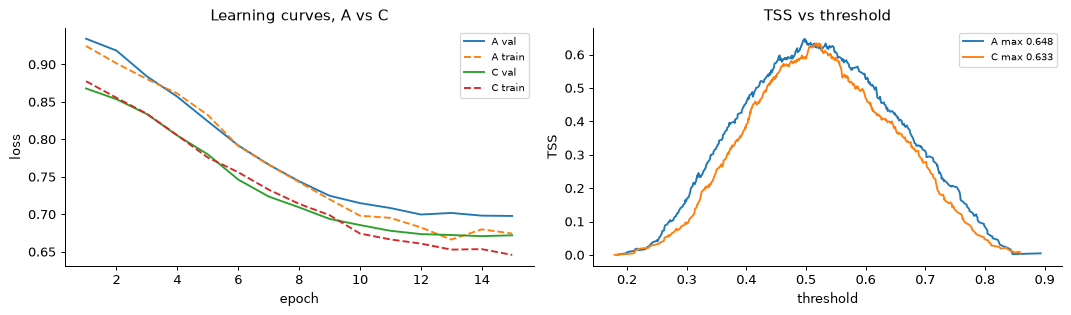

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for k in (base, "C"):
    hh = pd.DataFrame(runs[k]["history"])
    axes[0].plot(hh.epoch, hh.val_loss, label=f"{k} val"); axes[0].plot(hh.epoch, hh.train_loss, "--", label=f"{k} train")
    cur = metrics.tss_curve(y, runs[k]["p"]); axes[1].plot(cur.threshold, cur.tss, label=f"{k} max {runs[k]['metrics']['tss']:.3f}")
axes[0].set(xlabel="epoch", ylabel="loss", title=f"Learning curves, {base} vs C"); axes[0].legend(fontsize=8)
axes[1].set(xlabel="threshold", ylabel="TSS", title="TSS vs threshold"); axes[1].legend(fontsize=8)
fig.tight_layout()

## 10b. Seed check (A and B)

The A vs B gap is small, so A and B are rerun with seeds 0 and 1 (identical recipe and val cases). The spread across
seeds shows how much of a TSS difference training noise alone produces. Max TSS is taken per run, as above.

In [23]:
seed_rows = []
for k, base_id in (("A", "fme_A_resnet18"), ("B", "fme_B_deit_tiny")):
    seed_rows.append({"run": k, "seed": RECIPE["seed"], "tss": runs[k]["metrics"]["tss"], "roc_auc": runs[k]["metrics"]["roc_auc"],
                      "threshold": runs[k]["metrics"]["threshold"]})
    for s in RECIPE["extra_seeds"]:
        r = train.run(f"{base_id}_s{s}", FME["models"][k], TR, VA, c, FME, change=runs[k]["change"], seed=s)
        seed_rows.append({"run": k, "seed": s, "tss": r["metrics"]["tss"], "roc_auc": r["metrics"]["roc_auc"], "threshold": r["metrics"]["threshold"]})
seeds = pd.DataFrame(seed_rows)
display(seeds.round(3).set_index(["run", "seed"]).unstack("run"))
agg = seeds.groupby("run")[["tss", "roc_auc"]].agg(["mean", "std"]).round(3)
print("mean and sd over 3 seeds (sd with n-1):")
agg

tss        roc_auc        threshold       
run       A      B       A      B         A      B
seed                                              
0     0.629  0.602   0.874  0.873     0.495  0.115
1     0.617  0.652   0.869  0.878     0.484  0.245
42    0.648  0.626   0.878  0.873     0.498  0.108

mean and sd over 3 seeds (sd with n-1):


tss        roc_auc       
      mean    std    mean    std
run                             
A    0.631  0.016   0.874  0.005
B    0.627  0.025   0.875  0.003

## 11. Experiment table, findings, limitations, next steps

In [24]:
table = []
for k, r in runs.items():
    m, b = r["metrics"], r["metrics"]["bootstrap"]
    table.append({
        "Run": k, "Model / configuration": f"{r['model']['name']}" + (f" @{r['model']['upsample_to']}" if r["model"]["upsample_to"] else (" @128" if "deit" in r["model"]["name"] else "")) + f", recipe 0.5, seed {r['seed']}",
        "Change from baseline": r["change"],
        "Val TSS (95% CI) · ROC-AUC · PR-AUC*": f"{m['tss']:.3f} [{b['tss_ci95'][0]:.3f}, {b['tss_ci95'][1]:.3f}] · {m['roc_auc']:.3f} · {m['pr_auc_corrected']:.3f}",
        "threshold": round(m["threshold"], 3),
        "Dev cases (n, pos, HARPs)": f"{m['n']}, {m['n_pos']}, {m['n_harps']}",
        "Runtime / cost": f"{r['timing']['epoch_s_median']} s/epoch on {r['timing']['device']} · {r['model']['state_dict_mb']} MB · $0",
    })
pd.DataFrame(table).set_index("Run")

,Model / configuration,Change from baseline,Val TSS (95% CI) · ROC-AUC · PR-AUC*,threshold,"Dev cases (n, pos, HARPs)",Runtime / cost
Run,,,,,,
A,"resnet18.a1_in1k, recipe 0.5, seed 42",none (baseline),"0.648 [0.520, 0.744] · 0.878 · 0.289",0.498,"630, 210, 167",1.14 s/epoch on mps · 44.76 MB · $0
B,"deit_tiny_patch16_224.fb_in1k @128, recipe 0.5...",architecture only,"0.626 [0.510, 0.712] · 0.873 · 0.246",0.108,"630, 210, 167",1.08 s/epoch on mps · 21.66 MB · $0
C,"resnet18.a1_in1k, recipe 0.5, seed 42",flagged negatives (has_unattributed_mx) exclud...,"0.633 [0.492, 0.731] · 0.865 · 0.245",0.518,"630, 210, 167",1.02 s/epoch on mps · 44.76 MB · $0


\* PR-AUC prevalence-corrected (val negatives weighted to the natural 2015 count, 13.34 each). CPU latency is in
section 9. Seed check (section 10b): TSS over seeds 42, 0, 1 = A 0.631 ± 0.016, B 0.627 ± 0.025 (mean ± sd).

### Findings

1. **The pipeline works end to end** on real data: target list → JSOC export → cutouts → training → evaluation →
   run records (`experiments/results/`), with the leakage checks in section 3 passing.
2. **Both pretrained models learn a useful signal.** Val TSS 0.648 (A, ResNet-18) and 0.626 (B, DeiT-Tiny),
   ROC-AUC 0.878 and 0.873, on 630 val cases from 167 HARPs. For orientation only: the proposal's final target is
   TSS ≥ 0.5 on the replay test set (PR1), which is not evaluated here.
3. **CNN vs transformer: no difference at this data size.** The paired HARP bootstrap gives TSS(B) − TSS(A) =
   −0.021 (95% CI −0.110 to +0.072), and the seed-to-seed spread (0.602–0.652 for B, 0.617–0.648 for A) is as
   large as the gap; with seed 1, B is ahead. DeiT reaches this with half the parameters and half the size.
4. **Run C (flagged negatives excluded from training) did not help:** TSS 0.648 → 0.633 (paired CI −0.068 to
   +0.035). It traded recall (0.838 → 0.800) for fewer false alarms (0.190 → 0.167), and removed 63 of 420
   training negatives. The expected gain from cleaner labels did not show; at this size, the lost training data may
   matter more than the label noise. Single seed: the change (−0.016) is the size of A's seed sd (0.016).
5. **Failure pattern:** errors sit at the class boundary. Confident false positives are large regions with C-class
   flares (two possibly mislabelled); confident false negatives are small regions with flares at M1.0–M1.5
   (section 8).
6. **Probabilities are not calibrated** (corrected Brier skill score −4.1 for A, −2.0 for B; reliability diagram in
   section 7). Expected after the weighted loss; calibration (PR2, BSS > 0) is a later milestone.
7. **Practical constraints are met, except data throughput.** CPU, one 15-region timestep: 28.5 ms (A) and 20.0 ms
   (B); single region about 6 ms. Size 44.76 MB (A, inside the 50 MB target but tight) and 21.66 MB (B). About 1.1 s
   per training epoch on `mps` (target < 10 min). Cost $0. The JSOC export ran at 1,243 cutouts/h (queue wait median
   63 s per 35-record request), so the full 36,365-image set would take about 29 h at this rate, and the next
   planned subset (11,923 images) about 9.6 h, more than the 8.4 h the plan assumed.

### Limitations

- **Small, subsampled data.** 630 training and 630 val images (1,260 of 2,097 listed; the export was stopped after
  36 of 60 requests by design). Val negatives are subsampled to 1:2: TSS and ROC-AUC are unaffected, the other metrics are
  prevalence-corrected.
- **Optimistic thresholds.** Each max TSS is picked on the same val cases it is reported on.
- **Short training, fixed recipe.** 15 epochs, no tuning; ResNet's val loss was still falling at epoch 15
  (section 10), so longer training may help.
- **Single seed** for the CIs and for Run C; the seed check covers A and B only.
- **Aspect ratio:** regions are stretched to 128×128 (original width/height 0.74–4.34).
- Latency measured on the laptop, not yet inside the Docker image.

### Blocker and next steps

No blocker. The constraint is the JSOC export rate. Next:

1. Run the 8.4 h subset download overnight (all 1,086 train positives, 5,000 train negatives, the full 2015 val);
   files already downloaded are skipped. At the measured rate it needs about 9.6 h.
2. Rerun A, B and C on the full val at natural prevalence with 3 seeds each.
3. Then: longer training (val loss was still falling), calibration (PR2), a persistence baseline, and padding vs
   stretch (v2).